In [16]:
%load_ext autoreload
%autoreload 2

import torch

from dataloaders.sequence import SequenceDataModule
from propagators.tft_latent import PropagatorTFTLatent
from embeddings.resolver import get_encdec
import pytorch_lightning as pl

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
config = {
    "debug": False,
    "outpath": "./train_runs/dev",
    "outfolder": "run",
    "overwrite": True,
    "nexp": 1,
    "output_to_file": True,
    
    "nepochs": 5,
    "lrate": 1e-4,
    "wandb": False,
    "scheduler": False,
    "early_stopping": False,
    
    "likelihood": "Gaussian",
    "lielihood_args": {
        "prior_mu": 0.0,
        "prior_sigma": 1.0,
        "prior_strength": 0.0,
        "beta_nll": 0.0,
    },
    
    "dynamics_name": "XTC_graph",
    "data_args": {
        "tprfile": "./data_generation/ala2/solvated/300K/initialization/tpr_initial.tpr",
        "xtcfile": "./data_generation/ala2/solvated/300K/ala2_100ns/md.xtc",
        "selection": "(resname ALA or resname ACE or resname NME) and not element H",
        "datareader_type": "XTC_CHUNKS_CG",
        "cg_window": 4,
        # "dataset_type": "GRAPH",
        "dataset_type": "GRAPH_LATENT",
        "dataset_args": {
            "encoder_name": "BGE",
            "encoder_ckpt": "./train_runs/encoder/bge/run_1/checkpoints/best.ckpt",
        },
        "train_size": 2,
        "batch_size": 2,
        "validation_size": 2,
        "val_batch_size": 2,
        "num_workers": 1,
        "n_seq_per_sample": 8,
        "norm_type": "minmax",
    },
    "dataset_analyzer": "ala2",
    
    "propagator_name": "TFT",
    "encdec_name": "BGE",
    "encdec_ckpt": "./train_runs/encoder/bge/run_1/checkpoints/best.ckpt",
    "propagator_args": {
        "input_chunk_length": 8,
        "output_chunk_length": 4,
        "hidden_dim": 128,
        "lstm_layers": 2,
        "num_attention_heads": 2,
        "dropout": 0.0,
    },
    
    
    
}

In [18]:
input_chunk_length = config['propagator_args']['input_chunk_length']
output_chunk_length = config['propagator_args']['output_chunk_length']
n_seq_per_sample = config['data_args'].pop('n_seq_per_sample', 1)
config['data_args']['input_chunk_length'] = input_chunk_length
config['data_args']['output_chunk_length'] = output_chunk_length
config['data_args']['num_chunks_per_sequence'] = n_seq_per_sample
config['data_args']['datareader_type'] = config['data_args'].get('datareader_type', 'XTC_CHUNKS')
config['data_args']['datareader_args'] = {
    'xtcfile': config['data_args'].pop('xtcfile', None),
    'tprfile': config['data_args'].pop('tprfile', None),
    'selection': config['data_args'].pop('selection', None),
}
if config['data_args']['datareader_type'] == 'XTC_CHUNKS_CG':
    config['data_args']['datareader_args']['cg_window'] = config['data_args'].pop('cg_window', 1)
config['data_args']['workdir'] = config['outpath']
data_set = SequenceDataModule(**config['data_args'])




[Initializing module: XTCChunksCGReader]
[XTCChunksCGReader]: Loading topology from file ./data_generation/ala2/solvated/300K/initialization/tpr_initial.tpr
[XTCChunksCGReader]: Loading trajectory from file: ./data_generation/ala2/solvated/300K/ala2_100ns/md.xtc
Atom index mapping (original -> selected):
  Original index: 1 -> Selected index: 0 (Element: C, Name: CH3, Type: CT, Residue: ACE1)
  Original index: 5 -> Selected index: 1 (Element: C, Name: C, Type: C, Residue: ACE1)
  Original index: 6 -> Selected index: 2 (Element: O, Name: O, Type: O, Residue: ACE1)
  Original index: 7 -> Selected index: 3 (Element: N, Name: N, Type: N, Residue: ALA2)
  Original index: 9 -> Selected index: 4 (Element: C, Name: CA, Type: CT, Residue: ALA2)
  Original index: 11 -> Selected index: 5 (Element: C, Name: CB, Type: CT, Residue: ALA2)
  Original index: 15 -> Selected index: 6 (Element: C, Name: C, Type: C, Residue: ALA2)
  Original index: 16 -> Selected index: 7 (Element: O, Name: O, Type: O, 

100%|██████████| 320/320 [00:02<00:00, 139.04it/s]


Coarse-graining trajectory with window size 4...


 33%|███▎      | 1/3 [00:02<00:04,  2.32s/it]

Coarse-grained trajectory has 80 frames.


...

Coarse-grained trajectory has 0 frames.
[XTCChunksCGReader]: Finished reading trajectories.



[Initializing module: BondGraphLatentDataset]



[Initializing module: BondGraphLatentDataset]
[BondGraphLatentDataset]: Bond set (atom index pairs):
    (0, 1)
    (1, 2)
    (1, 3)
    (3, 4)
    (4, 5)
    (4, 6)
    (6, 7)
    (6, 8)
    (8, 9)
[BondGraphLatentDataset]: End - Bond set (atom index pairs)
[BondGraphLatentDataset]: Angle set (atom index triplets):
    [0, 1, 2]
    [0, 1, 2]
    [0, 1, 3]
    [0, 1, 3]
    [2, 1, 3]
    [2, 1, 3]
    [1, 3, 4]
    [1, 3, 4]
    [3, 4, 5]
    [3, 4, 5]
    [3, 4, 6]
    [3, 4, 6]
    [5, 4, 6]
    [5, 4, 6]
    [4, 6, 7]
    [4, 6, 7]
    [4, 6, 8]
    [4, 6, 8]
    [7, 6, 8]
    [7, 6, 8]
    [6, 8, 9]
    [6, 8, 9]
[BondGraphLatentDataset]: End - Angle set (atom index triplets)
[BondGraphLatentDataset]: Torsion set (atom index quartets):
    [0, 1, 3, 4]
    [0, 1, 3, 4]
    [2, 1, 3, 4]
    [2, 1, 3, 4]
    [1, 3, 4, 5]
    [1, 3, 4, 5]
  

Precomputing graphs: 100%|██████████| 80/80 [00:00<00:00, 202.20it/s]


[BondGraphLatentDataset]: Loaded graph dataset with 80 graphs
[BondGraphLatentDataset]: Number of bonds (nodes): 9
[BondGraphLatentDataset]: Node feature size: 3
[BondGraphLatentDataset]: Edge feature size: 3
[BondGraphLatentDataset]: Total number of edges: 42
[BondGraphLatentDataset]: Encoding graphs with provided encoder...
[BondGraphLatentDataset]: Encoding complete.



[Initializing module: BondGraphLatentDataset]



[Initializing module: BondGraphLatentDataset]
[BondGraphLatentDataset]: Bond set (atom index pairs):
    (0, 1)
    (1, 2)
    (1, 3)
    (3, 4)
    (4, 5)
    (4, 6)
    (6, 7)
    (6, 8)
    (8, 9)
[BondGraphLatentDataset]: End - Bond set (atom index pairs)
[BondGraphLatentDataset]: Angle set (atom index triplets):
    [0, 1, 2]
    [0, 1, 2]
    [0, 1, 3]
    [0, 1, 3]
    [2, 1, 3]
    [2, 1, 3]
    [1, 3, 4]
    [1, 3, 4]
    [3, 4, 5]
    [3, 4, 5]
    [3, 4, 6]
    [3, 4, 6]
    [5, 4, 6]
    [5, 4, 6]
    [4, 6, 7]
    [4, 6, 7]
    [4, 6, 8]
    [4, 6, 8]
    

Precomputing graphs: 100%|██████████| 80/80 [00:00<00:00, 201.26it/s]


[BondGraphLatentDataset]: Loaded graph dataset with 80 graphs
[BondGraphLatentDataset]: Number of bonds (nodes): 9
[BondGraphLatentDataset]: Node feature size: 3
[BondGraphLatentDataset]: Edge feature size: 3
[BondGraphLatentDataset]: Total number of edges: 42
[BondGraphLatentDataset]: Encoding graphs with provided encoder...
[BondGraphLatentDataset]: Encoding complete.
[SequenceDataModule]: Loaded dataset with 160 frames -> Train: 80, Validation: 80, Test: 0
[SequenceDataModule]: Datapoint shape: (128,)


In [30]:
n_points = 16
data = torch.stack([data_set.get_dataset()[i][0] for i in range(n_points)])
data = data.unsqueeze(0).reshape(-1, 8, data.shape[-1])
data.shape

torch.Size([2, 8, 128])

In [20]:
tdl = data_set.train_dataloader()

In [21]:
# prop_args = {}

# prop_args['likelihood'] = config.get('likelihood', 'QuantileRegression')
# prop_args['likelihood_args'] = config.get('likelihood_args', None)
# prop_args['latent_dim'] = 128
# prop_args['propagator_args'] = config['propagator_args']
# prop_args['lr'] = config.get('lrate', 1e-3)
# prop_args['weight_decay'] = config.get('weight_decay', 0.0) 
# prop_args['normIn'] = config.get('normIn', False)
# prop_args['scheduler'] = config.get('scheduler', None)
# prop_args['scheduler_args'] = config.get('scheduler_args', None)
# prop_args['outname'] = './temp'

# model = PropagatorTFTLatent(**prop_args)

In [22]:
# trainer_args = {}
# trainer_args['accelerator'] = 'auto'
# trainer_args['devices'] = 'auto'
# trainer_args['max_epochs'] = config['nepochs']
# trainer_args['log_every_n_steps'] = 1
# trainer_args['default_root_dir'] = './temp'
# trainer_args['num_sanity_val_steps'] = 0
# trainer = pl.Trainer(**trainer_args)

In [23]:
# trainer.fit(model, datamodule=data_set)

In [31]:
from propagators.tft_model.tft import ModifiedTFTModel as TFTModel
from likelihoods.modified_gaussian import ModifiedGaussianLikelihood as GaussianLikelihood
icl = 8
ocl = 4
lik = GaussianLikelihood(
    prior_mu = 0.0,
    prior_sigma = 1.0,
    prior_strength = 0.0,
    beta_nll = 0.0,
)
(
    variables_meta, 
    n_static_components, 
    categorical_embedding_sizes, 
    output_dim
) = TFTModel.collect_meta(
    input_chunk_length = icl,
    output_chunk_length = ocl,
    n_past_covariates = 0,
    n_future_covariates = 0,
    n_static_covariates = 0,
    n_targets = 128,
    add_relative_index = True,
    likelihood = lik,
)

prop_keywargs = {
            "input_chunk_length": icl,
            "output_chunk_length": ocl,
            "output_dim": output_dim,
            "variables_meta": variables_meta,
            "num_static_components": n_static_components,
            "hidden_size": 16,
            "lstm_layers": 1,
            "dropout": 0.0,
            "num_attention_heads": 1,
            "full_attention": False,
            "feed_forward": "GatedResidualNetwork",
            "hidden_continuous_size": 8,
            "categorical_embedding_sizes": categorical_embedding_sizes,
            "add_relative_index": True,
            "norm_type": 'LayerNorm',
            "retain_lstm_cell_state": True,
        }
model = TFTModel(**prop_keywargs)
out = model((data, None, None))
print(model._retained_cell_state.shape)

torch.Size([2, 16])


In [25]:
out = model((data, None, None))

In [2]:
import torch 

dm = torch.load('./dmods/v_6/datamodule.pth')


/tmp/ipykernel_644735/126878026.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  dm = torch.load('./dmods/v_6/datamodule.pth')
/mnt/projects/sne/Gohar/12.PROJECT_Surrogat

In [4]:
train_data = dm.get_train_dataset()

In [6]:
from embeddings.resolver import get_encdec

encdec_name = "BGE"
encdec_ckpt = "./train_runs/encoder/bge/run_1/checkpoints/best.ckpt"
encdec_cls = get_encdec(encdec_name)
encdec = encdec_cls.load_from_checkpoint(encdec_ckpt, datamodule=dm)

In [18]:
print(len(train_data))

66048


In [30]:
from tqdm import tqdm
import random
encdec.eval()
latents = []
for i in tqdm(range(len(train_data))):
    latent = encdec(train_data[i])[1]
    latents.append(latent.squeeze(0))
latents = torch.stack(latents, dim=0)

100%|██████████| 66048/66048 [11:40<00:00, 94.22it/s] 


In [32]:
mean = latents.mean(dim=0)
range_ = latents.max(dim=0).values - latents.min(dim=0).values

In [47]:
latents_normed = (latents - mean) / range_

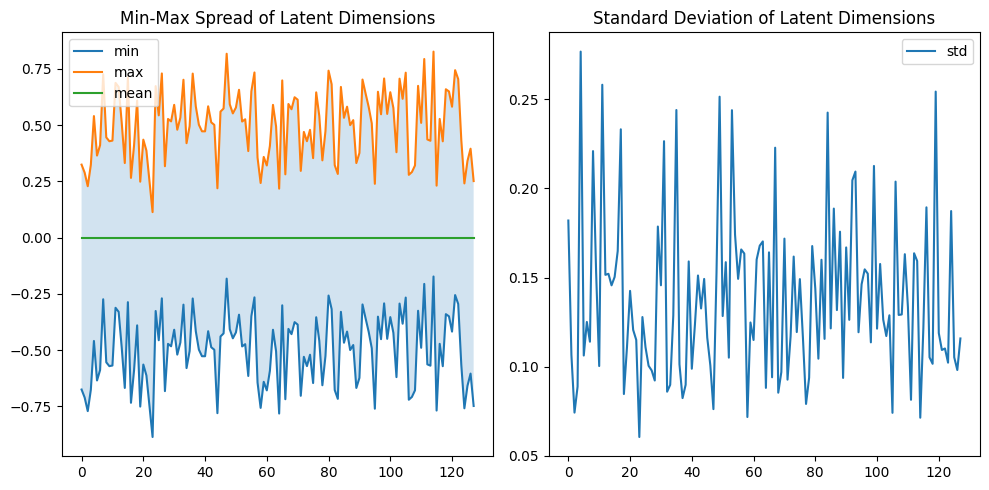

: 

In [ ]:
# plot min-max spread of the dataset with shape (points, 128)

from matplotlib import pyplot as plt
import numpy as np


data = latents_normed.detach().numpy()
data_min = data.min(axis=0)
data_max = data.max(axis=0)
data_mean = data.mean(axis=0)
data_std = data.std(axis=0)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(data_min, label='min')
plt.plot(data_max, label='max')
plt.plot(data_mean, label='mean')
plt.fill_between(np.arange(len(data_min)), data_min, data_max, alpha=0.2)
plt.legend()
plt.title('Min-Max Spread of Latent Dimensions')
plt.subplot(1, 2, 2)
plt.plot(data_std, label='std')
plt.legend()
plt.title('Standard Deviation of Latent Dimensions')
plt.tight_layout()
plt.show()
